# 02 – Explore IMD rainfall (2023)
Load one year of IMD 0.25° daily rain, convert to xarray, and inspect it.

In [1]:
import imdlib as imd

# Downloads the yearly .grd file into data/raw/ (gitignored)
data = imd.get_data('rain', 2023, 2023, fn_format='yearwise', file_dir='../data/raw')
ds = data.get_xarray()
ds

File already exists: ../data/raw/rain/2023.grd. Skipping download.
Download Successful !!!


<xarray.Dataset> Size: 51MB
Dimensions:  (time: 365, lat: 129, lon: 135)
Coordinates:
  * time     (time) datetime64[us] 3kB 2023-01-01 2023-01-02 ... 2023-12-31
  * lat      (lat) float64 1kB 6.5 6.75 7.0 7.25 7.5 ... 37.75 38.0 38.25 38.5
  * lon      (lon) float64 1kB 66.5 66.75 67.0 67.25 ... 99.25 99.5 99.75 100.0
Data variables:
    rain     (time, lat, lon) float64 51MB nan nan nan nan ... nan nan nan nan
Attributes:
    Conventions:  CF-1.7
    title:        IMD gridded data
    source:       https://imdpune.gov.in/
    history:      2026-10-26 14:54:07.138055 Python
    references:   
    comment:      
    crs:          epsg:4326

## Dimensions and coordinate ranges

In [2]:
rain = ds['rain']
print(dict(ds.sizes))
print('lat', float(ds.lat.min()), '->', float(ds.lat.max()))
print('lon', float(ds.lon.min()), '->', float(ds.lon.max()))

{'time': 365, 'lat': 129, 'lon': 135}
lat 6.5 -> 38.5
lon 66.5 -> 100.0


## Value range, sentinels, NaNs
imdlib already converts IMD's -999 'no data' marker to NaN, so no -999 should remain.

In [3]:
print('min', float(rain.min()), ' max', float(rain.max()))
print('negative values:', int((rain < 0).sum()))
print('NaN cells:', int(rain.isnull().sum()), 'of', rain.size, f'({float(rain.isnull().mean()):.0%})')

min 0.0  max 689.0372314453125
negative values: 0
NaN cells: 4544694 of 6356475 (71%)


## Sanity check: NaNs should be ocean / outside India, the same cells every day

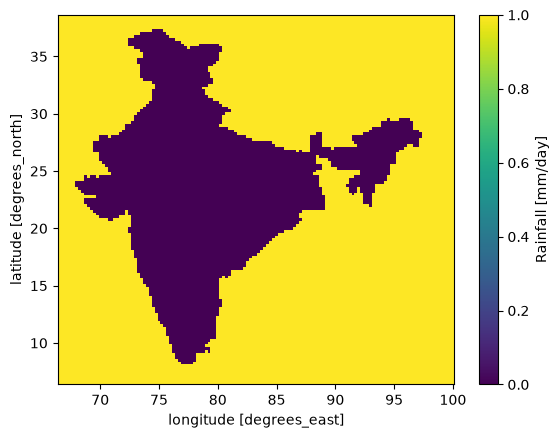

In [4]:
rain.isnull().all('time').plot();  # True where a cell is NaN all year